In [2]:
import functools
import numpy as np
import qiskit as qk
import qiskit.providers.fake_provider as qk_fp
import qiskit_dynamics as qk_d
# import qiskit_experiments as qk_e
from scipy.integrate import simpson
from scipy.linalg import sqrtm, expm
from scipy.optimize import curve_fit
import qutip as qt
from tqdm import tqdm

import sys

sys.path.append("../")
import pulse_simulator as ps

import matplotlib.pyplot as plt

# Experiments with default IBM gates

First, we activate the IBM service we are going to be using.

In [3]:
from qiskit_ibm_runtime import QiskitRuntimeService, Session, SamplerV2 as Sampler

with open("../ibm_token.txt", "r") as file:
    IBM_TOKEN = file.read()
service = QiskitRuntimeService(token=IBM_TOKEN, channel="ibm_quantum")

And we get backend information.

In [4]:
Units = 1e9

# Undo units
GHz = 1 / Units
MHz = 1e3 / Units
μs = Units / 1e3
ns = Units

# backend = qk_fp.FakeManila()
backend = service.get_backend("ibm_nazca")
dt = backend.configuration().dt * ns

# desired_duration = 225 # dt
desired_duration = 120  # dt

# Can be acquired with backend.configuration().timing_constraints['granularity']
# granularity = 16
granularity = backend.configuration().timing_constraints["granularity"]

GATE_TIME_SI_UNITS = desired_duration * dt / ns
# duration = ps.qiskit_closest_multiple_of_16(GATE_TIME_SI_UNITS, backend)
duration = ps.qiskit_closest_multiple(GATE_TIME_SI_UNITS, backend, granularity)
dt, granularity, duration

(0.5, 8, 120)

## XYXY Sequences

In [5]:
session = Session(backend=backend)
print(f"Session id: {session.session_id}")

Session id: csg9h04p7n0g0086rp40


In [6]:
sampler = Sampler(backend=backend, session=session)

In [7]:
def xyxy_sequence(n: int, q0: int, q1: int):
    qc = qk.QuantumCircuit(2)
    qc.sx(0)
    qc.sx(1)
    for _ in range(n):
        qc.x(0)
        qc.y(0)
        qc.x(0)
        qc.y(0)
        qc.x(1)
        qc.y(1)
        qc.x(1)
        qc.y(1)
    qc.sx(0)
    qc.sx(1)
    qc.measure_all()

    return qk.transpile(qc, basis_gates=["x", "sx", "rz", "id"], optimization_level=0)

In [12]:
example = xyxy_sequence(1, 0, 1)
example.draw()

┌────┐┌───┐┌───────┐┌───┐┌───┐┌───────┐┌───┐┌────┐ ░ ┌─┐   
   q_0: ┤ √X ├┤ X ├┤ Rz(π) ├┤ X ├┤ X ├┤ Rz(π) ├┤ X ├┤ √X ├─░─┤M├───
        ├────┤├───┤├───────┤├───┤├───┤├───────┤├───┤├────┤ ░ └╥┘┌─┐
   q_1: ┤ √X ├┤ X ├┤ Rz(π) ├┤ X ├┤ X ├┤ Rz(π) ├┤ X ├┤ √X ├─░──╫─┤M├
        └────┘└───┘└───────┘└───┘└───┘└───────┘└───┘└────┘ ░  ║ └╥┘
meas: 2/══════════════════════════════════════════════════════╩══╩═
                                                              0  1

In [15]:
lengths = list(range(1, 401, 4))
dd_circuits = [xyxy_sequence(i, 0, 1) for i in lengths]

In [16]:
dd_jobs = sampler.run(dd_circuits, shots=2048)

In [11]:
dd_jobs.job_id()

'csfn3zzbm6a0008971xg'

In [12]:
dd_jobs.status()

<JobStatus.DONE: 'job has successfully run'>

In [13]:
dd_jobs = service.job("csfn3zzbm6a0008971xg")

In [19]:
results = dd_jobs.result()
counts = []
for result in results:
    counts.append(result.data.meas.get_counts())

/var/folders/v_/cdntg9bj3fb76npbssx1kfnm0000gn/T/ipykernel_40493/394563590.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


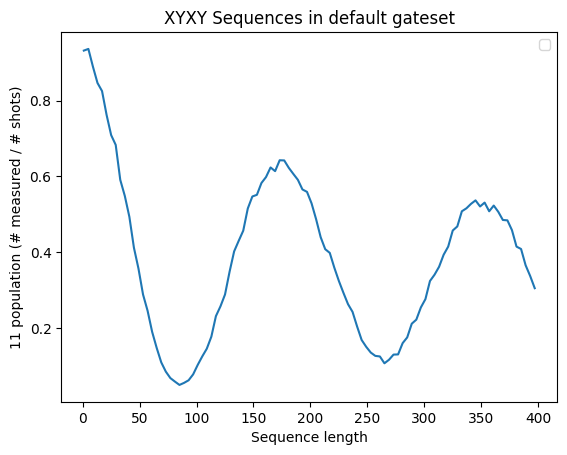

In [22]:
counts_11 = [count.get("11", 0) / 2048 for count in counts]

plt.plot(lengths, counts_11)
plt.xlabel("Sequence length")
plt.ylabel("11 population (# measured / # shots)")
plt.title("XYXY Sequences in default gateset")
plt.legend()
plt.show()

In [300]:
session.cancel()
session.close()
session.status()

'Closed'